---
title: "Lagrangian Mechanics — Level 2"
short_title: "06 Lagrangian Mechanics"
numbering:
  heading_2: true
  equation: true
---

# Lagrangian Mechanics

:::{seealso} Math for this topic
- [M5: Calculus of variations](../math/05-calculus-of-variations.ipynb)
- [M3: Multivariable calculus](../math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (not in Tipler & Mosca) | Start at Level 2 |
| **2** | **Taylor, ch. 6–7** | **Derive equations of motion from L = T − U in generalized coordinates; use Lagrange multipliers for constraint forces** |
| 3 | Goldstein, ch. 1–2 | D'Alembert's principle, Hamilton's principle in general, Noether's theorem |

The new skill at this level: replacing force bookkeeping with a single scalar function, written in whatever coordinates suit the problem

Math for this topic: M5, calculus of variations (and M3 for partial derivatives and multipliers).
:::

Exercises have separate hint and answer dropdowns. A small sympy helper below derives equations of motion from any Lagrangian, so you can check hand derivations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Hamilton's Principle

Define the **Lagrangian** as kinetic minus potential energy, $\mathcal{L} = T - U$, and the **action** of a path $q(t)$ between fixed endpoints as

$$
S = \int_{t_1}^{t_2}\mathcal{L}(q, \dot q, t)\,dt .
$$

:::{prf:theorem} Hamilton's principle
:label: thm-hamilton-principle

The path a system actually follows makes the action stationary. By M5, that means it satisfies the **Lagrange equations**, one for each coordinate:

$$
\frac{\partial\mathcal{L}}{\partial q_i} = \frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot q_i} .
$$ (eq-lagrange-eqs)
:::

**Check against Newton.** For a particle in Cartesian coordinates, $\mathcal{L} = \tfrac12m(\dot x^2 + \dot y^2 + \dot z^2) - U(x, y, z)$. Then $\partial\mathcal{L}/\partial x = -\partial U/\partial x = F_x$ and $\frac{d}{dt}\partial\mathcal{L}/\partial\dot x = m\ddot x$, so {eq}`eq-lagrange-eqs` is $F_x = m\ddot x$. The two formulations agree. Lagrange's version is the more useful one because it takes the same form in any coordinates.

## Generalized Coordinates and Constraints

A **generalized coordinate** is any set of numbers $q_1,\dots,q_n$ that pins down the configuration: angles, distances along a wire, anything convenient. The number of independent coordinates needed is the number of **degrees of freedom**.

A constraint that can be written as an equation among the coordinates (a pendulum rod: $x^2 + y^2 = \ell^2$; a bead on a wire) is **holonomic**. Choosing coordinates that satisfy the constraints automatically (the pendulum angle $\phi$) removes the constraint forces from the problem entirely. They do no work in any allowed motion, so they never enter $\mathcal{L}$.

:::{important} The recipe
1. Choose generalized coordinates, one per degree of freedom.
2. Write $T$ and $U$ in terms of them. $T$ is usually easiest from Cartesian velocities expressed in the new coordinates.
3. Form $\mathcal{L} = T - U$ and write one Lagrange equation per coordinate.
:::

In [2]:
# A reusable helper: equations of motion from a Lagrangian
t = sp.symbols("t")

def lagrange_equations(L, qs):
    # Return [d/dt dL/dqdot - dL/dq] for each coordinate q(t), simplified
    eqs = []
    for q in qs:
        qd = q.diff(t)
        eqs.append(sp.simplify(sp.diff(L.diff(qd), t) - L.diff(q)))
    return eqs

# Example: simple pendulum, angle phi from the downward vertical
m, l, gs = sp.symbols("m ell g", positive=True)
phi = sp.Function("phi")(t)
x, y = l * sp.sin(phi), -l * sp.cos(phi)
T = sp.Rational(1, 2) * m * (x.diff(t)**2 + y.diff(t)**2)
U = m * gs * y
print("pendulum:", lagrange_equations(sp.simplify(T - U), [phi])[0], "= 0")

pendulum: ell*m*(ell*Derivative(phi(t), (t, 2)) + g*sin(phi(t))) = 0


::::{prf:example} Atwood machine
:label: ex-atwood

Two masses $m_1$ and $m_2$ hang over a massless pulley on a string of fixed length. Find the acceleration.

:::{dropdown} Solution
One degree of freedom: let $x$ be the distance $m_1$ hangs below the pulley, so $m_2$ hangs $\ell - x$ below. Measuring heights downward,

$$
\mathcal{L} = \tfrac12(m_1 + m_2)\dot x^2 + m_1gx + m_2g(\ell - x) .
$$

The Lagrange equation gives $(m_1 + m_2)\ddot x = (m_1 - m_2)g$. The tension never appeared. To find it, see the section on Lagrange multipliers.
:::
::::

::::{prf:example} Bead on a spinning hoop
:label: ex-bead-hoop

A bead slides without friction on a circular hoop of radius $R$ that spins about its vertical diameter at constant angular velocity $\omega$. Let $\theta$ be the bead's angle from the bottom. Find the equation of motion.

:::{dropdown} Solution
The bead's distance from the axis is $R\sin\theta$, so its velocity has a part $R\dot\theta$ along the hoop and a part $\omega R\sin\theta$ around the axis. Its height is $-R\cos\theta$. So

$$
\mathcal{L} = \tfrac12mR^2\left(\dot\theta^2 + \omega^2\sin^2\theta\right) + mgR\cos\theta ,
$$

and the Lagrange equation is

$$
\ddot\theta = \left(\omega^2\cos\theta - \frac gR\right)\sin\theta .
$$

This is the Level 3 preview from the Newton's laws notes, derived without ever mentioning the normal force, which has two components and changes direction as the hoop turns. For $\omega^2 > g/R$, the bottom becomes unstable and the bead settles at $\cos\theta_0 = g/(R\omega^2)$.
:::
::::

In [3]:
th = sp.Function("theta")(t)
R, w = sp.symbols("R omega", positive=True)
L = sp.Rational(1, 2) * m * R**2 * (th.diff(t)**2 + w**2 * sp.sin(th)**2) + m * gs * R * sp.cos(th)
eq = lagrange_equations(L, [th])[0]
print("bead on hoop:", sp.solve(sp.Eq(eq, 0), th.diff(t, 2))[0])

bead on hoop: (R*omega**2*cos(theta(t)) - g)*sin(theta(t))/R


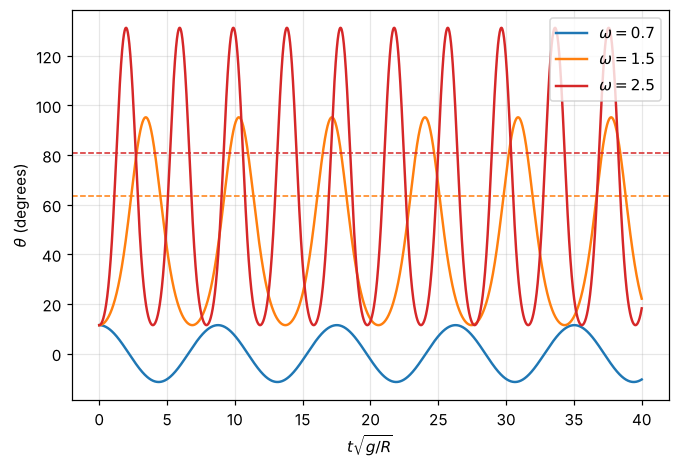

In [4]:
#| label: fig-bead-hoop-motion
#| caption: The bead released near the bottom (θ = 0.2 rad). Below the critical spin rate (√(g/R) = 1 here) it oscillates about the bottom; above it, it moves out and oscillates about the off-axis equilibrium (dashed).
gR = 1.0
t = np.linspace(0, 40, 4000)
fig, ax = plt.subplots()
for w, c in [(0.7, "tab:blue"), (1.5, "tab:orange"), (2.5, "tab:red")]:
    sol = solve_ivp(lambda s, y: [y[1], (w**2 * np.cos(y[0]) - gR) * np.sin(y[0])], (0, 40), [0.2, 0],
                    t_eval=t, rtol=1e-9)
    ax.plot(t, np.degrees(sol.y[0]), color=c, lw=1.6, label=rf"$\omega = {w}$")
    if w**2 > gR:
        ax.axhline(np.degrees(np.arccos(gR / w**2)), color=c, ls="--", lw=1)
ax.set_xlabel(r"$t\sqrt{g/R}$"); ax.set_ylabel(r"$\theta$ (degrees)"); ax.legend(); plt.show()

## A Two-Coordinate Example: the Spring Pendulum

A mass on a spring (natural length $\ell_0$, constant $k$) swings in a vertical plane. Use polar coordinates $(r, \phi)$ with $\phi$ from the downward vertical:

$$
\mathcal{L} = \tfrac12m\left(\dot r^2 + r^2\dot\phi^2\right) + mgr\cos\phi - \tfrac12k(r - \ell_0)^2 .
$$

The two Lagrange equations come out at once:

$$
m\ddot r = mr\dot\phi^2 + mg\cos\phi - k(r - \ell_0), \qquad
\frac{d}{dt}\left(mr^2\dot\phi\right) = -mgr\sin\phi .
$$

The first contains the centrifugal term; the second says the torque changes the angular momentum. Doing this with forces is possible but error-prone. The motion itself is nonlinear and, for large amplitudes, chaotic.

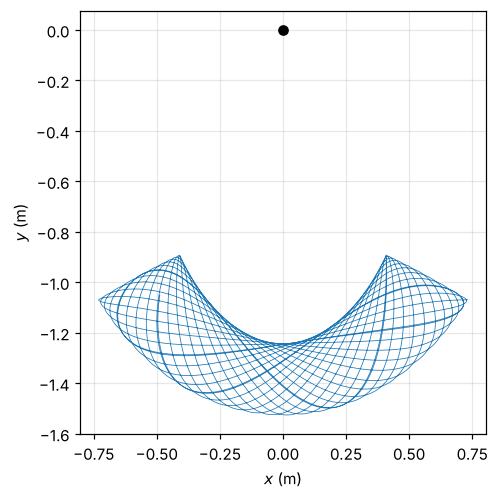

In [5]:
#| label: fig-spring-pendulum
#| caption: Path of a spring pendulum (ω_spring/ω_pendulum ≈ 2, a ratio where energy trades strongly between stretching and swinging). The bob's path is complicated even though the Lagrangian is three short terms.
m_, k_, l0, g_ = 1.0, 40.0, 1.0, 9.81
def rhs(s, y):
    r, ph, rd, phd = y
    return [rd, phd, r * phd**2 + g_ * np.cos(ph) - k_ / m_ * (r - l0), -(g_ * np.sin(ph) + 2 * rd * phd) / r]
r_eq = l0 + m_ * g_ / k_
sol = solve_ivp(rhs, (0, 30), [r_eq + 0.05, 0.6, 0, 0], max_step=0.005, rtol=1e-9)
r, ph = sol.y[0], sol.y[1]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(r * np.sin(ph), -r * np.cos(ph), lw=0.5)
ax.plot(0, 0, "ko"); ax.set_aspect("equal"); ax.set_xlabel("$x$ (m)"); ax.set_ylabel("$y$ (m)")
plt.show()

## Generalized Momenta and Cyclic Coordinates

Define the **generalized momentum** conjugate to $q_i$:

$$
p_i = \frac{\partial\mathcal{L}}{\partial\dot q_i} .
$$

For a Cartesian coordinate this is ordinary momentum; for an angle it is usually an angular momentum. The Lagrange equation reads $\dot p_i = \partial\mathcal{L}/\partial q_i$. So:

:::{prf:theorem} Cyclic coordinates
:label: thm-cyclic

If $\mathcal{L}$ does not depend on $q_i$ (the coordinate is **cyclic** or *ignorable*), its conjugate momentum $p_i$ is conserved.
:::

For a particle in a central potential, $\mathcal{L} = \tfrac12m(\dot r^2 + r^2\dot\phi^2) - U(r)$ has no $\phi$, so $p_\phi = mr^2\dot\phi$ is conserved. That is angular momentum conservation, now a one-line consequence of symmetry.

:::{tip} Do not solve the cyclic equation twice
For a cyclic coordinate, the conservation law **is** the Lagrange equation, already integrated once. Use $p_i = $ const directly. If $\dot q_i$ or $\ddot q_i$ appears in another coordinate's equation, substitute from the conservation law (differentiating it if you need $\ddot q_i$).
:::

### Energy

If $\mathcal{L}$ has no explicit $t$, the Beltrami identity from M5 gives a conserved quantity:

$$
h = \sum_i\dot q_i\frac{\partial\mathcal{L}}{\partial\dot q_i} - \mathcal{L} .
$$

When the coordinates are time-independent (so $T$ is a quadratic form in the $\dot q_i$), $h = T + U$, the total energy. When they are not, as with the spinning hoop, $h$ is still conserved, but it is not the energy. The hoop's motor does work on the bead, so $T + U$ changes while $h$ stays constant.

## Constraint Forces from Lagrange Multipliers

To find a constraint force, keep the constrained coordinate and impose the constraint $f(q) = 0$ with a multiplier (M3, M5):

$$
\frac{\partial\mathcal{L}}{\partial q_i} - \frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot q_i} + \lambda\frac{\partial f}{\partial q_i} = 0 .
$$

The term $\lambda\,\partial f/\partial q_i$ is the generalized constraint force.

In [6]:
# Pendulum tension via a multiplier: keep r as a coordinate with the constraint f = r - ell = 0
# (re-declare the symbols: the plotting cells above reused t as a NumPy array)
t = sp.symbols("t"); m, l, gs = sp.symbols("m ell g", positive=True)
r = sp.Function("r")(t); ph = sp.Function("phi")(t); lam = sp.symbols("lambda")
L = sp.Rational(1, 2) * m * (r.diff(t)**2 + r**2 * ph.diff(t)**2) + m * gs * r * sp.cos(ph)
f = r - l
eq_r = sp.diff(L, r) - sp.diff(L.diff(r.diff(t)), t) + lam * sp.diff(f, r)
eq_r = eq_r.subs({r.diff(t, 2): 0, r.diff(t): 0}).subs(r, l)    # impose the constraint
print("lambda =", sp.solve(eq_r, lam)[0])

lambda = -m*(ell*Derivative(phi(t), t)**2 + g*cos(phi(t)))


The result is $\lambda = -\left(m\ell\dot\phi^2 + mg\cos\phi\right)$: a force along $-\hat{r}$ of magnitude $mg\cos\phi + m\ell\dot\phi^2$, the string tension. It supports the radial part of gravity and supplies the centripetal force.

### Exercises

1. A bead slides on a frictionless straight wire that rotates in a horizontal plane at constant $\omega$ about one end. Find $r(t)$ if it starts at rest relative to the wire at $r_0$. Is $T$ conserved? Is $h$?
2. A particle moves on the inside of a frictionless cone $z = r\cot\alpha$ (vertex down). Using $(r, \phi)$, write $\mathcal{L}$ and identify a conserved quantity.
3. For a particle in a uniform gravitational field, which Cartesian momenta are conserved, and why?

:::{dropdown} Hints
1. $\mathcal{L} = \tfrac12m(\dot r^2 + \omega^2r^2)$.
2. $\dot z = \dot r\cot\alpha$, so $T = \tfrac12m(\dot r^2/\sin^2\alpha + r^2\dot\phi^2)$.
3. Which coordinates are missing from $\mathcal{L} = \tfrac12m(\dot x^2 + \dot y^2 + \dot z^2) - mgz$?
:::

:::{dropdown} Answers
1. $\ddot r = \omega^2r$, so $r = r_0\cosh\omega t$. $T$ grows (the motor does work); $h = \tfrac12m\dot r^2 - \tfrac12m\omega^2r^2$ is conserved.
2. $\mathcal{L} = \tfrac12m\left(\dot r^2/\sin^2\alpha + r^2\dot\phi^2\right) - mgr\cot\alpha$. $\phi$ is cyclic, so $mr^2\dot\phi$ is conserved; $h = E$ is also conserved.
3. $p_x$ and $p_y$: $x$ and $y$ are cyclic, which reflects the field's symmetry under horizontal translation.
:::

## Summary

- $\mathcal{L} = T - U$; the actual path makes $S = \int\mathcal{L}\,dt$ stationary, which gives one Lagrange equation per generalized coordinate.
- The equations have the same form in any coordinates, and constraint forces drop out when the coordinates respect the constraints.
- A cyclic coordinate has a conserved conjugate momentum; symmetry implies conservation.
- With no explicit time dependence, $h = \sum\dot q\,\partial\mathcal{L}/\partial\dot q - \mathcal{L}$ is conserved, and it equals $T + U$ when the coordinates do not move with time.
- Lagrange multipliers recover constraint forces when you need them.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.